<a href="https://colab.research.google.com/github/ryanaxiom/Applied-ML/blob/main/code/Day27_Carnegie_summary.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Instructions**: Before you begin, click **File > Save a copy in Drive** so you do not lose your work!

In [1]:
url = ("https://raw.githubusercontent.com/ryanaxiom/Applied-ML/main/data/carnegie_data.csv")

import pandas as pd
import numpy as np
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
carnegie_raw = pd.read_csv(url, encoding="cp1252")
carnegie = carnegie_raw.copy()
carnegie["research"] = carnegie["serd"] + carnegie["nonserd"]
d = carnegie[carnegie["research"].notna()].copy()
d["med_yn"] = (d["medical"] == 1).astype(int)
y = d["research"]
kf = KFold(n_splits=5, shuffle=True, random_state=309)
five = ["fallenr20", "totdeg", "facnum", "stem_rsd", "med_yn"]
print(carnegie.shape, d.shape)
print(round(np.sqrt(np.mean((y - y.mean())**2)), 1))

(3939, 102) (302, 103)
381304.9


In [2]:
def rmse_cv(model, X, y, folds=kf):
    mse = cross_val_score(model, X, y, cv=folds,
                          scoring="neg_mean_squared_error")
    return round(np.sqrt(-mse.mean()))
line = LinearRegression()
pipe = make_pipeline(StandardScaler(), Ridge())
ridge = GridSearchCV(pipe, {"ridge__alpha": np.logspace(-2, 4, 25)},
                     cv=kf, scoring="neg_mean_squared_error")
tree = DecisionTreeRegressor(max_depth=3, random_state=309)
rf = RandomForestRegressor(n_estimators=200, max_features="sqrt",
                           random_state=309)
gb = GradientBoostingRegressor(n_estimators=300, max_depth=1,
                               random_state=309)
models = {"line": line, "ridge": ridge, "tree": tree,
          "forest": rf, "boosting": gb}
for name, model in models.items():
    print(name, rmse_cv(model, d[five], y))


line 202133
ridge 201283
tree 238009
forest 200099
boosting 196404


In [3]:
naive = np.sqrt(np.mean((y - y.mean())**2))
on_ours = {}
for name, model in models.items():
    on_ours[name] = rmse_cv(model, d[five], y)
    under = round(100 * (1 - on_ours[name] / naive), 1)
    print(name, on_ours[name], str(under) + "% under the naive RMSE")
four = [on_ours[k] for k in ["line", "ridge", "forest", "boosting"]]
print("the four are", max(four) - min(four), "apart")
print("the tree is", on_ours["tree"] - on_ours["line"], "behind the line")
ridge.fit(d[five], y)
print("the search on all rows picks alpha",
      ridge.best_params_["ridge__alpha"])
print("its own best score", round(np.sqrt(-ridge.best_score_)))

line 202133 47.0% under the naive RMSE
ridge 201283 47.2% under the naive RMSE
tree 238009 37.6% under the naive RMSE
forest 200099 47.5% under the naive RMSE
boosting 196404 48.5% under the naive RMSE
the four are 5729 apart
the tree is 35876 behind the line
the search on all rows picks alpha 10.0
its own best score 201019


In [4]:
scores = {name: [] for name in models}
for seed in range(10):                        # ten reshuffles
    folds = KFold(n_splits=5, shuffle=True, random_state=seed)
    for name, model in models.items():
        scores[name].append(rmse_cv(model, d[five], y, folds))
for name in models:
    wins = np.sum(np.array(scores[name]) < np.array(scores["line"]))
    print(name, wins, end="  ")
print("line's range:", min(scores["line"]), max(scores["line"]))

line 0  ridge 7  tree 0  forest 3  boosting 0  line's range: 197770 210116


In [5]:
for name in models:
    wins = np.sum(np.array(scores[name]) < np.array(scores["line"]))
    print(name, min(scores[name]), max(scores[name]), wins)
gain = np.array(scores["line"]) - np.array(scores["ridge"])
print("line minus ridge:", [int(g) for g in gain])
print("largest", int(gain.max()), " median", float(np.median(gain)))
spread = max(scores["line"]) - min(scores["line"])
print("the line's range", spread, " ratio", round(spread / 5729, 2))

line 197770 210116 0
ridge 197681 208611 7
tree 242805 295495 0
forest 204643 211538 3
boosting 204118 221422 0
line minus ridge: [524, 1505, 445, 219, -162, -74, 89, 1435, 866, -776]
largest 1505  median 332.0
the line's range 12346  ratio 2.16


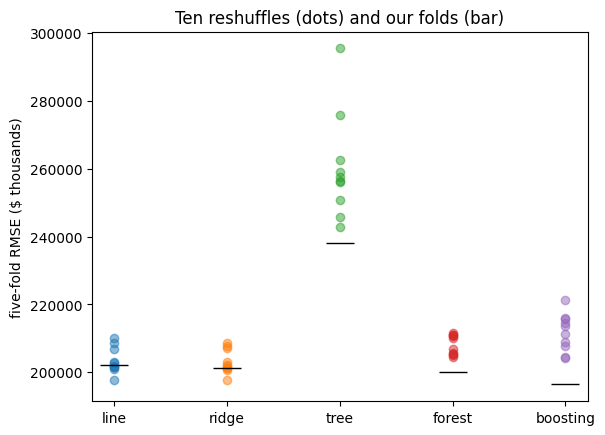

In [6]:
import matplotlib.pyplot as plt
for k, name in enumerate(models):
    plt.plot([k] * 10, scores[name], "o", alpha=0.5)
    plt.plot(k, on_ours[name], "k_", markersize=20)
plt.xticks(range(5), list(models))
plt.ylabel("five-fold RMSE ($ thousands)")
plt.title("Ten reshuffles (dots) and our folds (bar)")
plt.show()

In [7]:
def shuffled_rmse(model, col=None):
    rng, mses = np.random.default_rng(309), []
    for train, test in kf.split(d):
        model.fit(d[five].iloc[train], y.iloc[train])
        Xt = d[five].iloc[test].copy()
        if col is not None:                 # held-out rows only
            Xt[col] = rng.permutation(Xt[col].values)
        mses.append(np.mean((y.iloc[test] - model.predict(Xt))**2))
    return round(np.sqrt(np.mean(mses)))
for model in [line, rf]:
    base = shuffled_rmse(model)
    print(base, [shuffled_rmse(model, c) - base for c in five])

202133 [74129, 11287, 151310, 150839, 1827]
200099 [19998, 3669, 119232, 121786, 5411]
